# 04 · Make the next generation more accurate

Upload this notebook to Colab, select **CPU / Python 3**, and choose **Runtime → Run all**.
No repository clone, local assets, downloads, credentials, pretrained weights or GPU are required.
PyTorch, NumPy, Matplotlib and IPython are included in the standard Colab runtime.

**Before Run all, record your prediction:** will it learn all three rules, or mostly repeat C?
The lecture showed the first parameter change; this lab reveals the full outcome.

**What runs:** a real, tiny autoregressive categorical policy with 624 learnable logits.
It generates four pitch-class tokens; reward-weighted gradients update those logits.

**What improves:** compliance with symbolic constraints. This is not an LLM, YuE2 fine-tuning,
perceptual-quality measurement, or a full PPO/GRPO implementation.

| Stop | Minutes | Inspect |
|---|---:|---|
| 1 · Task and policy | 3 | Tokens, probabilities, verifier |
| 2 · One actual update | 4 | Baseline → detached advantage → log-probability → parameter change |
| 3 · Repeat and evaluate | 3 | Frozen baseline, fresh samples, curves |
| 4 · Listen and transfer | 2 | Synthesised plans, limitations, larger-model mapping |

## 1 · Task, policy and verifier (3 min)

> Generate **four notes in C major**, end on **C**, and use **at least three distinct pitch classes**.

Vocabulary: C C# D D# E F F# G G# A A# B.
At each position, the policy samples one token. Its state is the position and previous token:
a deliberately small **Markov approximation**, not a transformer.

Many sequences can pass; there is no target melody. We update the generator itself,
rather than select the best from an increasingly large candidate pool.

Uniform initialisation makes the mechanism visible. Real post-training usually replaces this
starting point with a pretrained or SFT checkpoint.

In [1]:
import copy, json, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.distributions import Categorical
from IPython.display import Audio, display

torch.set_num_threads(1)
torch.manual_seed(7)
np.random.seed(7)
NOTE_NAMES = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
LENGTH, VOCAB, START = 4, 12, 12
SCALE = torch.tensor([True, False, True, False, True, True,
                      False, True, False, True, False, True])
def names(tokens):
    return " ".join(NOTE_NAMES[int(x)] for x in tokens)
print("CPU task ready; vocabulary:", " ".join(NOTE_NAMES))

CPU task ready; vocabulary: C C# D D# E F F# G G# A A# B


In [2]:
class TinyPolicy(nn.Module):
    def __init__(self):
        super().__init__()
        # theta[position, previous token, next token]; initially uniform.
        self.logits = nn.Parameter(torch.zeros(LENGTH, VOCAB + 1, VOCAB))

    def rollout(self, n):
        previous = torch.full((n,), START, dtype=torch.long)
        tokens, token_logps = [], []
        for position in range(LENGTH):
            distribution = Categorical(logits=self.logits[position, previous])
            action = distribution.sample()
            tokens.append(action)
            token_logps.append(distribution.log_prob(action))
            previous = action
        # log pi(sequence) = sum of conditional token log-probabilities.
        return torch.stack(tokens, dim=1), torch.stack(token_logps, dim=1).sum(dim=1)

policy = TinyPolicy()
frozen = copy.deepcopy(policy)
print("Learnable parameters:", sum(p.numel() for p in policy.parameters()))

Learnable parameters: 624


The verifier is separate from the policy. Dense teaching reward helps exploration:

**reward = 0.55 × fraction in scale + 0.30 × ends on C + 0.15 × variety passes**

**Strict success** requires all three checks simultaneously.
A high mean reward does not imply every sequence passes.

In [3]:
def checks(tokens):
    in_scale = SCALE[tokens].float().mean(dim=1)
    ends_on_c = (tokens[:, -1] == 0).float()
    distinct = (tokens[:, :, None] == torch.arange(VOCAB)).any(dim=1).sum(dim=1)
    return in_scale, ends_on_c, (distinct >= 3).float()

def verify(tokens):
    key, home, variety = checks(tokens)
    return 0.55 * key + 0.30 * home + 0.15 * variety

def strict_success(tokens):
    key, home, variety = checks(tokens)
    return (key == 1) & (home == 1) & (variety == 1)

# The same hand-chosen teaching quartet as slides 7–8, not sampled model output.
examples = torch.tensor([[0, 4, 7, 0], [0, 0, 0, 0],
                         [1, 3, 6, 8], [1, 1, 1, 1]])
example_rewards = verify(examples)
example_advantages = example_rewards - example_rewards.mean()
print(f"Teaching-group mean: {example_rewards.mean().item():.2f}")
for x, r, a, ok in zip(examples, example_rewards, example_advantages, strict_success(examples)):
    print(f"{names(x):14s} reward={r.item():.2f}  advantage={a.item():+.2f}  pass={bool(ok)}")
assert torch.allclose(example_rewards, torch.tensor([1.0, 0.85, 0.15, 0.0]))

Teaching-group mean: 0.50
C E G C        reward=1.00  advantage=+0.50  pass=True
C C C C        reward=0.85  advantage=+0.35  pass=False
C# D# F# G#    reward=0.15  advantage=-0.35  pass=False
C# C# C# C#    reward=0.00  advantage=-0.50  pass=False


## 2 · One actual update (4 min)

The six conceptual operations correspond to the numbered lines in the function below:

~~~python
tokens, logp = policy.rollout(B * G)      # sample fresh trajectories
reward = verify(tokens)                  # score complete trajectories
adv = reward - group_mean(reward)        # compare within each prompt group
loss = -(adv.detach() * logp).mean()      # weight likelihood gradients
optimizer.zero_grad(); loss.backward()   # compute gradients
optimizer.step()                         # change policy parameters
~~~

All groups share the same instruction. G = 8 sequences form a group; B = 16 groups reduce noise.
A group baseline is **not a critic network**.

We use **centred, unnormalised advantages**, and the **sum** of token log-probabilities.
**detach** prevents differentiation through reward/advantage. The differentiable path is **logp**.
Positive advantage favours a sampled trajectory; it does not provide a verified local reward per note.

This is an **on-policy, group-centred REINFORCE / GRPO-style teaching update**.
Each batch is used for one step, then discarded. We omit standardisation, PPO likelihood ratios,
clipping, reference KL, replay and a learned critic. Reusing a batch for several updates would
require revisiting this objective. This is not a full GRPO trainer.

In [4]:
B, G = 16, 8
optimizer = torch.optim.Adam(policy.parameters(), lr=0.08)

def one_update(policy, optimizer):
    tokens, logp = policy.rollout(B * G)                  # 1 · sample
    reward = verify(tokens).reshape(B, G)                # 2 · score
    advantage = reward - reward.mean(dim=1, keepdim=True) # 3 · centre
    loss = -(advantage.detach() * logp.reshape(B, G)).mean() # 4 · objective
    optimizer.zero_grad()
    loss.backward()                                     # 5 · gradient
    gradient_norm = policy.logits.grad.norm().item()
    optimizer.step()                                    # 6 · update
    return {"tokens": tokens.detach(), "reward": reward.detach(),
            "advantage": advantage.detach(), "gradient_norm": gradient_norm}

before_first_step = policy.logits.detach().clone()
audit = one_update(policy, optimizer)
first_step_delta = (policy.logits.detach() - before_first_step).abs().max().item()
print("First group (one complete sequence per row):")
for tokens, reward, advantage in zip(audit["tokens"][:G],
                                    audit["reward"][0], audit["advantage"][0]):
    print(f"{names(tokens):14s} reward={reward.item():.3f}  advantage={advantage.item():+.3f}")
print(f"Gradient norm: {audit['gradient_norm']:.6f}")
print(f"Maximum parameter change after optimizer.step(): {first_step_delta:.6f}")
assert first_step_delta > 0

First group (one complete sequence per row):
C# G A A#      reward=0.425  advantage=-0.159
C G F G        reward=0.700  advantage=+0.116
A D A# D#      reward=0.425  advantage=-0.159
E G A# A       reward=0.562  advantage=-0.022
D F B C        reward=1.000  advantage=+0.416
F# F G# A      reward=0.425  advantage=-0.159
C# A A C#      reward=0.275  advantage=-0.309
D# A E C       reward=0.863  advantage=+0.278
Gradient norm: 0.040984
Maximum parameter change after optimizer.step(): 0.080000


## 3 · Reveal: all three rules, or repeated C? (3 min)

Revisit your prediction before reading the curves. Did parameter changes translate into
**all three** checks passing, or mainly easy components?

Complete **100 updates in total**, with fresh rollouts at every update.
The frozen baseline keeps its original logits.

Curve checkpoints use 4,096 sequences which are never sent to the optimiser.
Final reporting uses **another evaluation seed**, again with 4,096 samples per policy.
This is one fixed toy task, not a held-out composer/style/generalisation benchmark.
The renderer, reward and evaluation protocol remain fixed. There is no best-of-k selection.

In [5]:
@torch.no_grad()
def evaluate(model, seed=2026, n=4096):
    # Preserve the training RNG stream and model parameters.
    with torch.random.fork_rng():
        torch.manual_seed(seed)
        tokens, _ = model.rollout(n)
    key, home, variety = checks(tokens)
    return {
        "component_pass_rates": {
            "all_notes_in_scale": (key == 1).float().mean().item(),
            "ends_on_c": home.mean().item(),
            "variety": variety.mean().item(),
        },
        "reward": verify(tokens).mean().item(),
        "success": strict_success(tokens).float().mean().item(),
        "distinct_plans": int(torch.unique(tokens, dim=0).shape[0]),
        "examples": tokens[:5].clone(),
    }

STEPS = 100
assert STEPS >= 1
history = [(0, evaluate(frozen)), (1, evaluate(policy))]
started = time.perf_counter()
for step in range(2, STEPS + 1):
    one_update(policy, optimizer)
    if step % 10 == 0:
        history.append((step, evaluate(policy)))
training_seconds = time.perf_counter() - started
baseline = evaluate(frozen, seed=99)
updated = evaluate(policy, seed=99)
print(f"Completed {STEPS} updates; loop time on this runtime: {training_seconds:.2f} s")
print("Evaluation uses fresh samples from the unchanged task.")

Completed 100 updates; loop time on this runtime: 0.50 s
Evaluation uses fresh samples from the unchanged task.


In [6]:
summary = {
    "seed": 7, "updates": STEPS, "parameters": policy.logits.numel(),
    "evaluation_seed": 99, "evaluation_samples": 4096,
    "frozen_reward": baseline["reward"], "updated_reward": updated["reward"],
    "frozen_success": baseline["success"], "updated_success": updated["success"],
    "frozen_component_pass_rates": baseline["component_pass_rates"],
    "updated_component_pass_rates": updated["component_pass_rates"],
    "first_step_gradient_norm": audit["gradient_norm"],
    "frozen_distinct_plans": baseline["distinct_plans"],
    "updated_distinct_plans": updated["distinct_plans"],
    "first_step_parameter_delta": first_step_delta,
}
print(json.dumps(summary, indent=2))

{
  "seed": 7,
  "updates": 100,
  "parameters": 624,
  "evaluation_seed": 99,
  "evaluation_samples": 4096,
  "frozen_reward": 0.48981934785842896,
  "updated_reward": 0.9933013319969177,
  "frozen_success": 0.0146484375,
  "updated_success": 0.969482421875,
  "frozen_component_pass_rates": {
    "all_notes_in_scale": 0.1220703125,
    "ends_on_c": 0.080810546875,
    "variety": 0.958984375
  },
  "updated_component_pass_rates": {
    "all_notes_in_scale": 0.98046875,
    "ends_on_c": 0.9892578125,
    "variety": 0.995849609375
  },
  "first_step_gradient_norm": 0.04098397120833397,
  "frozen_distinct_plans": 3704,
  "updated_distinct_plans": 263,
  "first_step_parameter_delta": 0.07999993860721588
}


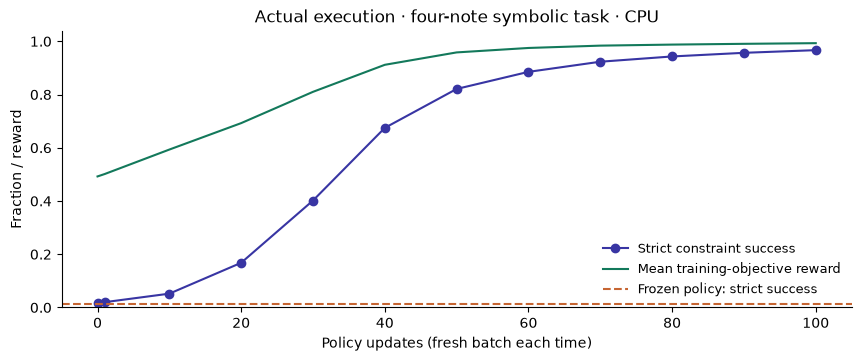

In [7]:
steps = [step for step, result in history]
fig, ax = plt.subplots(figsize=(8.5, 3.5), layout="constrained")
ax.plot(steps, [r["success"] for _, r in history], "o-", color="#3835A3",
        label="Strict constraint success")
ax.plot(steps, [r["reward"] for _, r in history], "-", color="#13795B",
        label="Mean training-objective reward")
ax.axhline(baseline["success"], color="#C66532", linestyle="--",
           label="Frozen policy: strict success")
ax.set(xlabel="Policy updates (fresh batch each time)", ylabel="Fraction / reward",
       ylim=(0, 1.04), title="Actual execution · four-note symbolic task · CPU")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=9)
plt.show()
plt.close(fig)

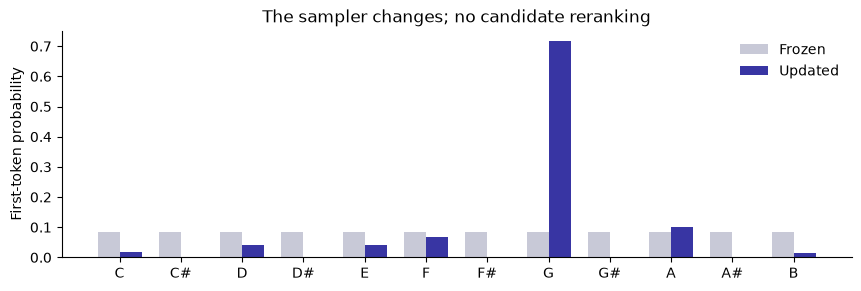

In [8]:
before_probs = frozen.logits[0, START].detach().softmax(dim=-1).numpy()
after_probs = policy.logits[0, START].detach().softmax(dim=-1).numpy()
x = np.arange(VOCAB)
fig, ax = plt.subplots(figsize=(8.5, 2.8), layout="constrained")
ax.bar(x - 0.18, before_probs, width=0.36, color="#C8C9D7", label="Frozen")
ax.bar(x + 0.18, after_probs, width=0.36, color="#3835A3", label="Updated")
ax.set_xticks(x, NOTE_NAMES)
ax.set(ylabel="First-token probability", title="The sampler changes; no candidate reranking")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()
plt.close(fig)

Read **both** strict success and the distinct-plan count. Variety within a sequence does not
guarantee diversity across outputs. The valid set is also smaller than the full space: compare diversity among valid outputs before attributing a lower raw count to unwanted mode collapse.

**Try afterwards:** change a reward weight or add a constraint, then **Run all** to reset policy
and optimiser. Set STEPS = 1 to inspect just the explicit first update; STEPS must be at least 1.

## 4 · Listen, then map to a larger model (2 min)

Here are the first five samples from each policy under the same evaluation seed.
Each player synthesises **only the first listed sample**, without selecting the nicest one.
Fixed-duration sine tones sonify pitch tokens; they do not measure musical quality.
No public YuE2 recording is used for this training experiment.

In [9]:
RATE = 16000
def sonify(tokens):
    parts = []
    for token in tokens:
        midi = 60 + int(token)
        t = np.arange(int(0.28 * RATE)) / RATE
        frequency = 440.0 * 2 ** ((midi - 69) / 12)
        envelope = np.sin(np.pi * np.arange(len(t)) / len(t)) ** 2
        tone = 0.2 * np.sin(2 * np.pi * frequency * t) * envelope
        parts.extend([tone, np.zeros(int(0.04 * RATE))])
    return np.concatenate(parts)

for label, result in [("Frozen policy", baseline), ("Updated policy", updated)]:
    print(label)
    for sequence in result["examples"]:
        print(" ", names(sequence), "pass=", bool(strict_success(sequence[None])[0]))
    display(Audio(sonify(result["examples"][0]), rate=RATE, autoplay=False))

Frozen policy
  G# G# C D# pass= False
  G# F# A G# pass= False
  G C D F pass= False
  G E B G# pass= False
  D# F G A pass= False


Updated policy
  G B C C pass= True
  G F B C pass= True
  G F D C pass= True
  G E B C pass= True
  G F G C pass= True


### The same conceptual loop, scaled up

| Toy cell | Larger autoregressive planner |
|---|---|
| Logits table at position / previous token | Conditional network logits from prompt and prefix |
| Four categorical samples | Autoregressive generation with masks and stop rules |
| Explicit symbolic verifier | Symbolic checks and/or validated audio/preference feedback |
| Group-centred rewards | Per-prompt advantages with documented normalisation |
| Sum of token log-probabilities | Log-probabilities of sampled output tokens; exclude prompt/padding |
| One fresh batch → one optimiser step | On-policy step, or a defined ratio/clipping/KL objective |

If generation used **no_grad**, recompute differentiable log-probabilities under the trainable policy.
Keep old/reference policies and advantages detached as required by the chosen objective.
LoRA reduces trainable weights; it does not replace this probability path.

For the proposed YuE2-inspired study, update the **ABC planner** and hold downstream rendering
fixed. Define the planner likelihood interface and validate feedback before any training.
Acoustic flow-matching components need their own formulation. FR3E/TreePO-inspired branching
changes sampling and credit assignment; this notebook does not implement their full estimators.

**Finish:** What changed in the policy? Which constraints improved?
What evidence is still needed to claim better music?

### Context and references
- [GRPO / DeepSeekMath](https://arxiv.org/abs/2402.03300)
- [FR3E](https://arxiv.org/abs/2507.07017) · [TreePO](https://arxiv.org/abs/2508.17445)
- [YuE2 project and public song cases](https://map-yue2.github.io/)
- The lecture's public case requests 160 BPM but declares Q:1/4=175 in its ABC score.
  This is a source-field observation; waveform tempo has not been measured.